# Added Signals and Models

To recap 
1. The first notebook established how the returns are setup and the proper normalize (their volatility cross-sectionally) for each contract
2. The second notebook examine the returns of long-only for the backtest and then tried a generic momentum signal, although the momentum signal worked in-sample it failed greatly out-of-sample.

What this notebook will do is that it will add more price-action/time series signals into our model, and rather than using the factor as the signal to trade it will be fitted into a model. The overall goal is to setup a model ready for the atlernative and machine learning while *enhancing* it with all of the data that is currently available. This notebook will specifically cover
1. The use of Logistic and OLS models to test and predict returns
2. The basis for how those models will be analyzed and the performance they generate, how to measure their in-sample vs. out-of-sample loss
3. How they perform when features are added and a framework for adding features

All of these are necessary features for moving towards alternative sentiment data and machine learning models

# Packages

In [1]:
import os
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# Paths and Global Variables

In [2]:
note_path = os.getcwd()
repo_path = os.path.abspath(os.path.join(note_path, ".."))
data_path = os.path.join(repo_path, "data")
zone_path = os.path.join(data_path, "ZoneImputedFirstRateData")

In [3]:
day_renamer = {
    "day_after"   : "Day After",
    "day_before"  : "Day Before",
    "post_meeting": "Post Meeting",
    "pre_meeting" : "Pre Meeting"}

zone_renamer = {
    "zone1": "Day Before",
    "zone2": "Before Meeting",
    "zone3": "After Meeting",
    "zone4": "Day After"}

sample_renamer = {
    "lday_vol" : "Prior Day",
    "lzone_vol": "Prior Event"}

vol_renamer = {
    "lday"       : "Prior Day",
    "lzone"      : "Prior Event",
    "combined"   : "Prior Day and Event",
    "raw_rtn"    : "Raw Return",
    "impute_open": "Raw Return"}

param_renamer = {
    "const"    : "Const",
    "lday_vol" : "Prior Day Vol",
    "lzone_vol": "Prio Event Vol"}

tmp_renamer = {
    "name"    : "Trading Zone",
    "vol_type": "Vol Estimator",
    "ticker"  : "Contract"}

sample_renamer_ = {
    "in_sample" : "In-Sample",
    "out_sample": "Out-Sample",
    "train_test": "Train-Test"}

replacer = {**day_renamer, **zone_renamer, **sample_renamer, **param_renamer, **vol_renamer, **tmp_renamer, **sample_renamer_}

In [4]:
import sys; sys.path.append(os.path.join(repo_path, "src"))
from SignalGenerator import SignalGenerator

# Fitting the historical performance signal

Before we begin adding more signals to the model lets first start by fitting the signals to the return. We'll use cumulative volatility normalized returns over the trading period as the endogenous target, this can be changed in the future but for now to make it easier we'll use this. The feature that we pass through to the model will be the average prior event return of the volatility normalized returns

In [5]:
logit_is = SignalGenerator().apply_model(spec_name = "logit__cum_rtn__lag_mean_rtn", scheme = "in_sample")
ols_is   = SignalGenerator().apply_model(spec_name = "ols__cum_rtn__lag_mean_rtn", scheme = "in_sample")

df_is = (pd
    .concat([
        logit_is.assign(model = "logit"),
        ols_is.assign(model = "ols")])
    .loc[lambda x: x.vol_type == "combined"])

The first part we want to examine is how similar are the trading signals between the OLS and Logistic. 

In [6]:
df_signals = (df_is
    [["model", "meeting_id", "zone", "name", "signal", "ticker"]]
    .drop_duplicates())

df_matched = (df_signals
    .pivot(index = ["meeting_id", "zone", "name", "ticker"], columns = "model", values = "signal")
    .apply(lambda x: np.where(x > 0, 1, 0))
    .assign(match = lambda x: np.where(x.ols == x.logit, "matched", "not matched"))
    .reset_index()
    .drop(columns = ["logit", "ols"])
    .groupby(["zone", "name", "ticker", "match"])
    .agg("count")
    .reset_index()
    .pivot(index = ["ticker", "name", "zone"], columns = "match", values = "meeting_id")
    .assign(cuml_val = lambda x: x.sum(axis = 1))
    .reset_index()
    .melt(id_vars = ["ticker", "name", "zone", "cuml_val"])
    .assign(prop = lambda x: x.value / x.cuml_val)
    .loc[lambda x: x.match == "matched"])

In [7]:
df_signal_corr = (df_signals
    .pivot(index = ["meeting_id", "zone", "name", "ticker"], columns = "model", values = "signal")
    .reset_index()
    .drop(columns = ["meeting_id"])
    .groupby(["zone", "name", "ticker"])
    .agg("corr")
    .loc[lambda x: x.ols != 1]
    .reset_index())

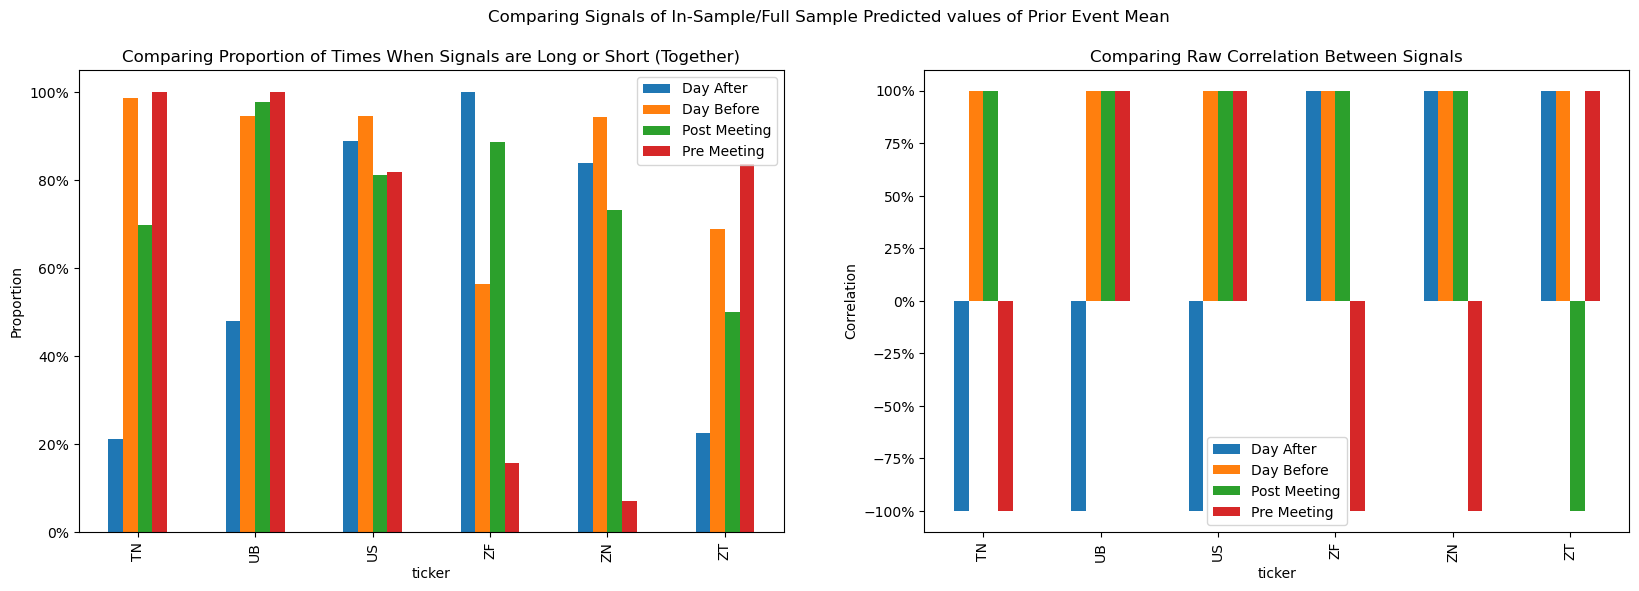

In [8]:


fig, axes = plt.subplots(ncols = 2, figsize = (20,6))

(df_matched
    .rename(columns = {"name": ""})
    .pivot(index = "ticker", columns = "", values = "prop")
    .rename(columns = replacer)
    .plot(
        ylabel = "Proportion",
        kind   = "bar", 
        ax     = axes[0],
        title  = "Comparing Proportion of Times When Signals are Long or Short (Together)"))

(df_signal_corr
    .rename(columns = {"name": ""})
    .pivot(index = "ticker", columns = "", values = "ols")
    .rename(columns = replacer)
    .plot(
        kind   = "bar", 
        ax     = axes[1],
        ylabel = "Correlation",
        title  = "Comparing Raw Correlation Between Signals"))

fig.suptitle("Comparing Signals of In-Sample/Full Sample Predicted values of Prior Event Mean")
for ax in axes.flatten(): ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))